In [1]:
# ============================================================
# 1 · Imports
# ============================================================

import os
import glob
import warnings
from pathlib import Path

import h5py
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display, clear_output
import ipywidgets as widgets

warnings.filterwarnings("ignore")

plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["image.cmap"] = "viridis"

In [35]:
# ============================================================
# 2 · Import extracted PPP sigma algorithms
# ============================================================
import importlib
import ppp_sigma_algorithms
importlib.reload(ppp_sigma_algorithms)

from ppp_sigma_algorithms import (
    EPS_LOG,
    prepare_grid,
    ppp_loglik_score,
    ppp_default_MMD,
    score_grid,
    score_sigma_zero,
    gaussianize_grid,
    optimize_sigma_for_grid_naive,
    optimize_sigma_for_grid,
    gaussian_kernel_and_first_derivative,
    gaussian_kernel_and_derivatives,
    eval_score_grad_sigma,
    eval_score_grad_hess_sigma,
    get_selected_interval_from_best_idx,
    quadratic_peak,
    refine_sigma_with_first_derivative,
    optimize_sigma_newton_robust_with_history,
    optimize_sigma_hybrid_group_then_grad,
    optimize_sigma_ternary_for_grid,
    optimize_sigma_golden_for_grid,
    optimize_sigma_dispatch,
)

print("Imported ppp_sigma_algorithms successfully.")

Imported ppp_sigma_algorithms successfully.


In [36]:
# ============================================================
# 3 · Configuration & Path Setup
# ============================================================

# Adjust these paths if needed
H5_DIRS = {
    "test_gen_data_meric_1500_13606074": (
        "/mnt/c/Users/uik04723/Repositories/gen_data_metric"
        "/test_gen_data_meric_1500_13606074/20260327_133317/metric_eval_data/test"
    ),
    "test_gen_data_meric_13600264": (
        "/mnt/c/Users/uik04723/Repositories/gen_data_metric"
        "/test_gen_data_meric_13600264/20260326_150824/metric_eval_data/test"
    ),
    "test_gen_data_meric_1500_13603608_LR_load_model40000": (
        "/mnt/c/Users/uik04723/Repositories/gen_data_metric"
        "/test_gen_data_meric_1500_13603608/20260327_012815/metric_eval_data/test"
    ),
}

ACTIVE_MODEL = "test_gen_data_meric_13600264"
H5_DIR = H5_DIRS[ACTIVE_MODEL]

assert os.path.isdir(H5_DIR), f"H5 directory not found: {H5_DIR}"

GT_DOT_SIZE = 16

h5_files = sorted(glob.glob(os.path.join(H5_DIR, "rank*.h5")))

print(f"Active model : {ACTIVE_MODEL}")
print(f"H5_DIR       : {H5_DIR}")
print(f"Found {len(h5_files)} h5 file(s)")
for p in h5_files:
    print(" ", p)

Active model : test_gen_data_meric_13600264
H5_DIR       : /mnt/c/Users/uik04723/Repositories/gen_data_metric/test_gen_data_meric_13600264/20260326_150824/metric_eval_data/test
Found 4 h5 file(s)
  /mnt/c/Users/uik04723/Repositories/gen_data_metric/test_gen_data_meric_13600264/20260326_150824/metric_eval_data/test/rank00.h5
  /mnt/c/Users/uik04723/Repositories/gen_data_metric/test_gen_data_meric_13600264/20260326_150824/metric_eval_data/test/rank01.h5
  /mnt/c/Users/uik04723/Repositories/gen_data_metric/test_gen_data_meric_13600264/20260326_150824/metric_eval_data/test/rank02.h5
  /mnt/c/Users/uik04723/Repositories/gen_data_metric/test_gen_data_meric_13600264/20260326_150824/metric_eval_data/test/rank03.h5


In [37]:
# ============================================================
# 4 · H5 Helpers
# ============================================================

def list_h5_samples(h5_paths):
    entries = []
    for path in h5_paths:
        with h5py.File(path, "r") as f:
            for key in sorted(f.keys()):
                entries.append((path, key))
    return entries


def load_h5_sample(h5_path, sample_key):
    with h5py.File(h5_path, "r") as f:
        grp = f[sample_key]
        img         = grp["img"][:]
        pred_lambda = grp["pred_lambda"][:].astype(np.float64)
        gt_support  = grp["gt_support"][:].astype(np.float64)

    H, W = pred_lambda.shape
    expected_count = float(pred_lambda.sum())
    gt_count = int((gt_support > 0).sum())

    return {
        "img": img,
        "pred_lambda": pred_lambda,
        "gt_support": gt_support,
        "ppp": {
            "H": H,
            "W": W,
            "img_area": H * W,
            "expected_count": expected_count,
            "gt_count": gt_count,
            "count_error": expected_count - gt_count,
        },
        "meta": {
            "h5_file": os.path.basename(h5_path),
            "sample_key": sample_key,
            "h5_path": h5_path,
        },
    }


all_samples = list_h5_samples(h5_files)

print(f"Total samples across all rank files: {len(all_samples)}")
print("First 5 entries:")
for entry in all_samples[:5]:
    print(" ", os.path.basename(entry[0]), "/", entry[1])

Total samples across all rank files: 500
First 5 entries:
  rank00.h5 / sample_000000
  rank00.h5 / sample_000001
  rank00.h5 / sample_000002
  rank00.h5 / sample_000003
  rank00.h5 / sample_000004


In [38]:
# ============================================================
# 5 · Visualization helper
# ============================================================

def show_sample_triptych(sample, title_prefix=""):
    img = sample["img"]
    pred_lambda = sample["pred_lambda"]
    gt_support = sample["gt_support"]
    ppp = sample["ppp"]
    meta = sample["meta"]

    ys, xs = np.where(gt_support > 0)

    fig, axes = plt.subplots(1, 3, figsize=(21, 5))

    axes[0].imshow(img, aspect="auto")
    axes[0].set_title(f"{title_prefix}Image\n{meta['sample_key']}")
    axes[0].axis("off")

    im = axes[1].imshow(pred_lambda, cmap="hot", aspect="auto")
    axes[1].set_title(rf"{title_prefix}Predicted $\lambda$" + f"\nE[N]={ppp['expected_count']:.2f}")
    axes[1].axis("off")
    plt.colorbar(im, ax=axes[1], fraction=0.046, pad=0.04)

    axes[2].imshow(img, aspect="auto")
    axes[2].scatter(xs, ys, s=GT_DOT_SIZE, c="lime", linewidths=0, alpha=0.9)
    axes[2].set_title(f"{title_prefix}GT overlay\nN={ppp['gt_count']}")
    axes[2].axis("off")

    plt.tight_layout()
    plt.show()

In [39]:
# ============================================================
# 6 · Sampling Helpers
# ============================================================

def sample_ppp_by_thinning(
    lambda_grid: np.ndarray,
    *,
    pixel_area: float | None = None,
    rng: np.random.Generator | None = None,
):
    if rng is None:
        rng = np.random.default_rng()

    lam = np.asarray(lambda_grid, dtype=np.float64)
    assert np.all(lam >= 0)
    H, W = lam.shape

    lambda_max = lam.max()
    if lambda_max == 0:
        return np.zeros((0, 2)), 0, 0.0, 0

    area_total = H * W
    Lambda_hom = lambda_max * area_total
    N_prop = rng.poisson(Lambda_hom)

    if N_prop == 0:
        return np.zeros((0, 2)), 0, lambda_max, 0

    xs = rng.random(N_prop) * W
    ys = rng.random(N_prop) * H
    xi = np.clip(xs.astype(int), 0, W - 1)
    yi = np.clip(ys.astype(int), 0, H - 1)

    lam_x = lam[yi, xi]
    accept_prob = lam_x / lambda_max
    keep = rng.random(N_prop) < accept_prob

    points_xy = np.stack([xs[keep], ys[keep]], axis=1)
    return points_xy, points_xy.shape[0], float(lambda_max), N_prop


def point_list_to_count_grid(points_xy, shape):
    H, W = shape
    grid = np.zeros((H, W), dtype=np.float64)

    if points_xy is None or len(points_xy) == 0:
        return grid

    points_xy = np.asarray(points_xy, dtype=np.float64)
    xs = np.floor(points_xy[:, 0]).astype(int)
    ys = np.floor(points_xy[:, 1]).astype(int)

    valid = (xs >= 0) & (xs < W) & (ys >= 0) & (ys < H)
    xs = xs[valid]
    ys = ys[valid]

    np.add.at(grid, (ys, xs), 1.0)
    return grid


def sample_point_cloud_from_lambda(
    pred_lambda,
    rng=None,
    mode="thinning",
    gt_count=None,
    block_size=8,
    placement="weighted",
    pixel_area=1.0,
):
    rng = np.random.default_rng() if rng is None else rng
    lam = np.asarray(pred_lambda, dtype=np.float64)

    if lam.ndim != 2:
        raise ValueError("pred_lambda must be 2D")
    if not np.all(np.isfinite(lam)):
        raise ValueError("pred_lambda contains NaN/Inf")
    if np.any(lam < 0):
        raise ValueError("pred_lambda contains negative values")

    H, W = lam.shape

    if mode == "thinning":
        points_xy, n_points, lambda_max, n_prop = sample_ppp_by_thinning(
            lam,
            pixel_area=pixel_area,
            rng=rng,
        )

        point_grid = point_list_to_count_grid(points_xy, (H, W))

        sampled_meta = {
            "mode": "thinning",
            "num_points": int(n_points),
            "grid_count_sum": int(point_grid.sum()),
            "binary_count": int((point_grid > 0).sum()),
            "lambda_max": float(lambda_max),
            "n_proposals": int(n_prop),
            "expected_count_input": float(lam.sum()),
        }
        return point_grid, sampled_meta

    raise ValueError("Currently only mode='thinning' is included in this test notebook.")

In [40]:
# ============================================================
# Helper: Extract sigma-score pairs from current algo outputs
# ============================================================

import numpy as np


def extract_eval_rows_from_result(res, *, h5_file, sample_key, input_type, algo):
    rows = []

    if res is None:
        return rows

    # --------------------------------------------------------
    # grid_naive / grid
    # --------------------------------------------------------
    if ("sigma_grid" in res) and ("scores" in res):
        sigma_arr = np.asarray(res["sigma_grid"], dtype=np.float64)
        score_arr = np.asarray(res["scores"], dtype=np.float64)

        n = min(len(sigma_arr), len(score_arr))
        for i in range(n):
            rows.append({
                "h5_file": h5_file,
                "sample_key": sample_key,
                "input_type": input_type,
                "algo": algo,
                "stage": "main",
                "eval_idx": int(i),
                "sigma": float(sigma_arr[i]),
                "score": float(score_arr[i]),
            })
        return rows

    # --------------------------------------------------------
    # newton / ternary / golden / direct history-based methods
    # --------------------------------------------------------
    if ("sigma_history" in res) and ("score_history" in res):
        sigma_arr = np.asarray(res["sigma_history"], dtype=np.float64)
        score_arr = np.asarray(res["score_history"], dtype=np.float64)

        n = min(len(sigma_arr), len(score_arr))
        for i in range(n):
            rows.append({
                "h5_file": h5_file,
                "sample_key": sample_key,
                "input_type": input_type,
                "algo": algo,
                "stage": "main",
                "eval_idx": int(i),
                "sigma": float(sigma_arr[i]),
                "score": float(score_arr[i]),
            })
        return rows

    # --------------------------------------------------------
    # hybrid: coarse + refinement
    # --------------------------------------------------------
    if "coarse" in res:
        coarse = res.get("coarse", None)
        if coarse is not None and ("sigma_grid" in coarse) and ("scores" in coarse):
            sigma_arr = np.asarray(coarse["sigma_grid"], dtype=np.float64)
            score_arr = np.asarray(coarse["scores"], dtype=np.float64)

            n = min(len(sigma_arr), len(score_arr))
            for i in range(n):
                rows.append({
                    "h5_file": h5_file,
                    "sample_key": sample_key,
                    "input_type": input_type,
                    "algo": algo,
                    "stage": "coarse",
                    "eval_idx": int(i),
                    "sigma": float(sigma_arr[i]),
                    "score": float(score_arr[i]),
                })

        refinement = res.get("refinement", None)
        if refinement is not None and ("sigma_history" in refinement) and ("score_history" in refinement):
            sigma_arr = np.asarray(refinement["sigma_history"], dtype=np.float64)
            score_arr = np.asarray(refinement["score_history"], dtype=np.float64)

            n = min(len(sigma_arr), len(score_arr))
            for i in range(n):
                rows.append({
                    "h5_file": h5_file,
                    "sample_key": sample_key,
                    "input_type": input_type,
                    "algo": algo,
                    "stage": "refinement",
                    "eval_idx": int(i),
                    "sigma": float(sigma_arr[i]),
                    "score": float(score_arr[i]),
                })

    return rows

In [41]:
# ============================================================
# 6 · Interactive sample selection tool
# ============================================================

selected_samples = []   # list of (h5_path, sample_key)

n = len(all_samples)

slider = widgets.IntSlider(
    value=0,
    min=0,
    max=max(0, n - 1),
    step=1,
    description="Sample:",
    continuous_update=False,
    layout=widgets.Layout(width="700px"),
)

btn_add = widgets.ToggleButton(
    value=False,
    description="☆ Add to selection",
    button_style="",
    layout=widgets.Layout(width="180px"),
)

btn_prev = widgets.Button(
    description="← Prev",
    layout=widgets.Layout(width="100px"),
)

btn_next = widgets.Button(
    description="Next →",
    layout=widgets.Layout(width="100px"),
)

btn_clear = widgets.Button(
    description="Clear selection",
    button_style="warning",
    layout=widgets.Layout(width="150px"),
)

btn_print = widgets.Button(
    description="Print selection",
    layout=widgets.Layout(width="130px"),
)

lbl_status = widgets.Label(value="0 selected")

plot_out = widgets.Output()
select_out = widgets.Output()


def _entry_of_idx(idx):
    h5_path, key = all_samples[idx]
    return (h5_path, key)


def _entry_label(entry):
    h5_path, key = entry
    return f"{os.path.basename(h5_path)} / {key}"


def _update_button_state(idx):
    entry = _entry_of_idx(idx)
    is_selected = entry in selected_samples
    btn_add.value = is_selected
    btn_add.description = "★ In selection" if is_selected else "☆ Add to selection"
    btn_add.button_style = "success" if is_selected else ""


def _refresh_status():
    lbl_status.value = f"{len(selected_samples)} selected"


def _render_selection_list():
    with select_out:
        clear_output(wait=True)
        print("Selected samples:")
        if not selected_samples:
            print("  (none)")
        else:
            for i, entry in enumerate(selected_samples):
                print(f"  {i:3d}: {_entry_label(entry)}")


def _render_current(idx):
    sample = load_h5_sample(*all_samples[idx])
    with plot_out:
        clear_output(wait=True)
        show_sample_triptych(sample, title_prefix=f"[{idx}] ")


def _full_refresh(idx):
    _update_button_state(idx)
    _refresh_status()
    _render_current(idx)
    _render_selection_list()


def _on_slider_change(change):
    if change["name"] == "value":
        _full_refresh(change["new"])


def _on_toggle_change(change):
    if change["name"] != "value":
        return

    idx = slider.value
    entry = _entry_of_idx(idx)

    if change["new"]:
        if entry not in selected_samples:
            selected_samples.append(entry)
    else:
        if entry in selected_samples:
            selected_samples.remove(entry)

    _full_refresh(idx)


def _on_prev_clicked(_):
    slider.value = max(slider.min, slider.value - 1)


def _on_next_clicked(_):
    slider.value = min(slider.max, slider.value + 1)


def _on_clear_clicked(_):
    selected_samples.clear()
    _full_refresh(slider.value)


def _on_print_clicked(_):
    _render_selection_list()


slider.observe(_on_slider_change, names="value")
btn_add.observe(_on_toggle_change, names="value")
btn_prev.on_click(_on_prev_clicked)
btn_next.on_click(_on_next_clicked)
btn_clear.on_click(_on_clear_clicked)
btn_print.on_click(_on_print_clicked)

controls = widgets.HBox([btn_prev, btn_next, btn_add, btn_clear, btn_print])
ui = widgets.VBox([slider, controls, lbl_status, plot_out, select_out])

display(ui)
_full_refresh(0)

In [42]:
# ============================================================
# 7 · Optional: inspect current selected samples as plain list
# ============================================================

print(f"{len(selected_samples)} selected samples")
for i, entry in enumerate(selected_samples):
    print(f"{i:3d}: {os.path.basename(entry[0])} / {entry[1]}")

3 selected samples
  0: rank00.h5 / sample_000000
  1: rank00.h5 / sample_000002
  2: rank00.h5 / sample_000003


In [43]:
# ============================================================
# 8 · Define all algorithms to be run
#    with all currently available parameters made explicit
# ============================================================

POINT_SAMPLING_MODE = "thinning"   # "thinning" or "block_bernoulli"
SIGMA_GRID = np.linspace(0.0, 120.0, 40)

ALGORITHM_SPECS = {
    # "grid_naive": dict(
    #     method="grid_naive",
    #     sigma_grid=SIGMA_GRID,
    #     verbose=False,
    #     eps_h=EPS_LOG,
    # ),

    "grid_group": dict(
        method="grid",
        sigma_grid=SIGMA_GRID,
        verbose=False,
        truncate=4.0,
        eps_h=EPS_LOG,
    ),

    # "newton": dict(
    #     method="newton",
    #     initial_checks=(0.0, 1.0, 50.0, 100.0, 120.0),
    #     verbose=False,
    #     sigma_min=0.0,
    #     sigma_max=120.0,
    #     max_iter=20,
    #     tol_g=1e-6,
    #     tol_sigma=1e-2,
    #     min_step=2.0,
    #     max_step=20.0,
    #     eps_h=EPS_LOG,
    # ),

    "hybrid": dict(
        method="hybrid",
        sigma_max=120.0,
        n_coarse=5,
        loss_tol=1e-3,
        truncate=4.0,
        refine_max_iter=50,
        verbose=False,
    ),

    "ternary": dict(
        method="ternary",
        sigma_min=0.0,
        sigma_max=120.0,
        max_iter=30,
        tol_sigma=0.01,
        eps_h=EPS_LOG,
        check_zero=True,
        verbose=False,
    ),

    "golden": dict(
        method="golden",
        sigma_min=0.0,
        sigma_max=120.0,
        max_iter=30,
        tol_sigma=0.5,
        eps_h=EPS_LOG,
        check_zero=True,
        verbose=False,
    ),
}

print("Algorithms:")
for k, v in ALGORITHM_SPECS.items():
    print(f"  {k}:")
    for kk, vv in v.items():
        print(f"    {kk} = {vv}")

Algorithms:
  grid_group:
    method = grid
    sigma_grid = [  0.           3.07692308   6.15384615   9.23076923  12.30769231
  15.38461538  18.46153846  21.53846154  24.61538462  27.69230769
  30.76923077  33.84615385  36.92307692  40.          43.07692308
  46.15384615  49.23076923  52.30769231  55.38461538  58.46153846
  61.53846154  64.61538462  67.69230769  70.76923077  73.84615385
  76.92307692  80.          83.07692308  86.15384615  89.23076923
  92.30769231  95.38461538  98.46153846 101.53846154 104.61538462
 107.69230769 110.76923077 113.84615385 116.92307692 120.        ]
    verbose = False
    truncate = 4.0
    eps_h = 1e-12
  hybrid:
    method = hybrid
    sigma_max = 120.0
    n_coarse = 5
    loss_tol = 0.001
    truncate = 4.0
    refine_max_iter = 50
    verbose = False
  ternary:
    method = ternary
    sigma_min = 0.0
    sigma_max = 120.0
    max_iter = 30
    tol_sigma = 0.01
    eps_h = 1e-12
    check_zero = True
    verbose = False
  golden:
    method = gol

In [44]:
# ============================================================
# 9 · Run all algorithms on all selected samples
#     for both:
#     - heatmap
#     - sampled point cloud
# ============================================================

import time
import numpy as np
import pandas as pd

if len(selected_samples) == 0:
    raise ValueError("No samples selected. Use the interactive tool first.")

results = []
eval_rows = []

for sample_idx, (h5_path, sample_key) in enumerate(selected_samples):
    print("=" * 110)
    print(f"[{sample_idx + 1}/{len(selected_samples)}] {os.path.basename(h5_path)} / {sample_key}")

    sample = load_h5_sample(h5_path, sample_key)
    pred_lambda = sample["pred_lambda"]
    gt_support = sample["gt_support"]
    ppp = sample["ppp"]
    meta = sample["meta"]

    sampled_pc_grid, sampled_pc_meta = sample_point_cloud_from_lambda(
        pred_lambda,
        rng=np.random.default_rng(sample_idx),
        mode="thinning",
        gt_count=ppp["gt_count"],
    )

    inputs_to_test = {
        # "heatmap": {
        #     "grid": pred_lambda,
        #     "input_meta": {},
        # },
        "sampled_pointcloud": {
            "grid": sampled_pc_grid,
            "input_meta": sampled_pc_meta,
        },
    }

    for input_type, input_payload in inputs_to_test.items():
        grid = input_payload["grid"]
        input_meta = input_payload["input_meta"]

        print(f"  INPUT: {input_type}")

        for algo_name, algo_kwargs in ALGORITHM_SPECS.items():
            run_kwargs = dict(algo_kwargs)

            # verbose output der Algos anschalten
            run_kwargs["verbose"] = False

            print(f"    -> {algo_name}")

            try:
                t0 = time.perf_counter()

                res = optimize_sigma_dispatch(
                    grid,
                    gt_support,
                    score_kind="loglik", # mmd
                    **run_kwargs,
                )

                runtime_sec = time.perf_counter() - t0

                best_sigma = float(res.get("best_sigma", np.nan))
                best_score = float(res.get("best_score", np.nan))
                status = str(res.get("status", "ok"))

                print(
                    f"       DONE | "
                    f"time={runtime_sec:8.4f}s | "
                    f"opt_sigma={best_sigma:10.6f} | "
                    f"opt_score={best_score:12.6f} | "
                    f"status={status}"
                )

                results.append({
                    "h5_file": meta["h5_file"],
                    "sample_key": meta["sample_key"],
                    "input_type": input_type,
                    "expected_count": float(ppp["expected_count"]),
                    "gt_count": int(ppp["gt_count"]),
                    "algo": algo_name,
                    "best_sigma": best_sigma,
                    "best_score": best_score,
                    "status": status,
                    "runtime_sec": float(runtime_sec),
                    "sampled_num_points": (
                        int(input_meta.get("num_points")) if input_type == "sampled_pointcloud" else np.nan
                    ),
                    "sampled_grid_count_sum": (
                        int(input_meta.get("grid_count_sum")) if input_type == "sampled_pointcloud" else np.nan
                    ),
                    "sampled_binary_count": (
                        int(input_meta.get("binary_count")) if input_type == "sampled_pointcloud" else np.nan
                    ),
                    "result_obj": res,
                })

                # ----------------------------------------------------
                # sigma/score pairs aus dem bestehenden Resultat ziehen
                # ----------------------------------------------------
                eval_rows.extend(
                    extract_eval_rows_from_result(
                        res,
                        h5_file=meta["h5_file"],
                        sample_key=meta["sample_key"],
                        input_type=input_type,
                        algo=algo_name,
                    )
                )

            except Exception as e:
                err_msg = f"ERROR: {type(e).__name__}: {e}"
                print(f"       {err_msg}")

                results.append({
                    "h5_file": meta["h5_file"],
                    "sample_key": meta["sample_key"],
                    "input_type": input_type,
                    "expected_count": float(ppp["expected_count"]),
                    "gt_count": int(ppp["gt_count"]),
                    "algo": algo_name,
                    "best_sigma": np.nan,
                    "best_score": np.nan,
                    "status": err_msg,
                    "runtime_sec": np.nan,
                    "sampled_num_points": (
                        int(input_meta.get("num_points")) if input_type == "sampled_pointcloud" else np.nan
                    ),
                    "sampled_grid_count_sum": (
                        int(input_meta.get("grid_count_sum")) if input_type == "sampled_pointcloud" else np.nan
                    ),
                    "sampled_binary_count": (
                        int(input_meta.get("binary_count")) if input_type == "sampled_pointcloud" else np.nan
                    ),
                    "result_obj": None,
                })

df_results = pd.DataFrame(results)
df_eval = pd.DataFrame(eval_rows)

print("\nDone.")
print(f"Rows in df_results: {len(df_results)}")
print(f"Rows in df_eval   : {len(df_eval)}")

[1/3] rank00.h5 / sample_000000
  INPUT: sampled_pointcloud
    -> grid_group
       DONE | time=  5.6386s | opt_sigma= 43.076923 | opt_score=    4.304258 | status=ok
    -> hybrid
       DONE | time=  5.0734s | opt_sigma= 40.354398 | opt_score=    4.292173 | status=refined_with_first_derivative
    -> ternary
       DONE | time= 11.0789s | opt_sigma= 40.873224 | opt_score=    4.292315 | status=ok
    -> golden
       DONE | time=  5.3173s | opt_sigma= 40.814006 | opt_score=    4.292310 | status=ok
[2/3] rank00.h5 / sample_000002
  INPUT: sampled_pointcloud
    -> grid_group
       DONE | time=  5.4051s | opt_sigma= 24.615385 | opt_score=    6.466161 | status=ok
    -> hybrid
       DONE | time=  4.7729s | opt_sigma= 27.808572 | opt_score=    6.442591 | status=refined_with_first_derivative
    -> ternary
       DONE | time=  7.2373s | opt_sigma= 25.907052 | opt_score=    6.458127 | status=ok
    -> golden
       DONE | time=  3.1955s | opt_sigma= 25.952350 | opt_score=    6.457814 | st

In [45]:
df_results[df_results['input_type'] == 'sampled_pointcloud']

,h5_file,sample_key,input_type,expected_count,gt_count,algo,best_sigma,best_score,status,runtime_sec,sampled_num_points,sampled_grid_count_sum,sampled_binary_count,result_obj
0,rank00.h5,sample_000000,sampled_pointcloud,106.851817,67,grid_group,43.076923,4.304258,ok,5.638620,111,111,111,"{'sigma_grid': [0.0, 3.076923076923077, 6.1538..."
1,rank00.h5,sample_000000,sampled_pointcloud,106.851817,67,hybrid,40.354398,4.292173,refined_with_first_derivative,5.073350,111,111,111,"{'best_sigma': 40.35439762044895, 'best_score'..."
2,rank00.h5,sample_000000,sampled_pointcloud,106.851817,67,ternary,40.873224,4.292315,ok,11.078912,111,111,111,"{'best_sigma': 40.87322419846817, 'best_score'..."
3,rank00.h5,sample_000000,sampled_pointcloud,106.851817,67,golden,40.814006,4.292310,ok,5.317251,111,111,111,"{'best_sigma': 40.81400589503589, 'best_score'..."
4,rank00.h5,sample_000002,sampled_pointcloud,156.930782,220,grid_group,24.615385,6.466161,ok,5.405115,149,149,149,"{'sigma_grid': [0.0, 3.076923076923077, 6.1538..."
5,rank00.h5,sample_000002,sampled_pointcloud,156.930782,220,hybrid,27.808572,6.442591,refined_with_first_derivative,4.772900,149,149,149,"{'best_sigma': 27.808572471631994, 'best_score..."
6,rank00.h5,sample_000002,sampled_pointcloud,156.930782,220,ternary,25.907052,6.458127,ok,7.237281,149,149,149,"{'best_sigma': 25.90705151052297, 'best_score'..."
7,rank00.h5,sample_000002,sampled_pointcloud,156.930782,220,golden,25.952350,6.457814,ok,3.195542,149,149,149,"{'best_sigma': 25.95234969498257, 'best_score'..."
8,rank00.h5,sample_000003,sampled_pointcloud,172.858436,191,grid_group,33.846154,5.633309,ok,5.409523,167,167,167,"{'sigma_grid': [0.0, 3.076923076923077, 6.1538..."
9,rank00.h5,sample_000003,sampled_pointcloud,172.858436,191,hybrid,30.000000,5.588869,coarse_better_than_refinement,3.755718,167,167,167,"{'best_sigma': 30.0, 'best_score': 5.588869462..."


In [46]:
# ============================================================
# Re-evaluate all best_sigmas with the same canonical scorer
# raw, no caching, using scipy Gaussian blur
# ============================================================

import numpy as np
import pandas as pd

# ------------------------------------------------------------
# choose one sample / input_type to inspect
# ------------------------------------------------------------
h5_file_sel = "rank02.h5"
sample_key_sel = "sample_000050"
input_type_sel = "sampled_pointcloud"   # or "heatmap"

# ------------------------------------------------------------
# load the corresponding grid again
# ------------------------------------------------------------
selected_h5 = [h5_path for h5_path, key in selected_samples if os.path.basename(h5_path) == h5_file_sel and key == sample_key_sel]
print(f"found {len(selected_h5)} matching h5 files for selection criteria")
sample = load_h5_sample(
    selected_h5[0],
    sample_key_sel,
)

pred_lambda = sample["pred_lambda"]
gt_support = sample["gt_support"]
ppp = sample["ppp"]

if input_type_sel == "heatmap":
    grid_eval = pred_lambda
elif input_type_sel == "sampled_pointcloud":
    sampled_pc_grid, sampled_pc_meta = sample_point_cloud_from_lambda(
        pred_lambda,
        rng=np.random.default_rng(0),
        mode=POINT_SAMPLING_MODE,
        gt_count=ppp["gt_count"],
    )
    grid_eval = sampled_pc_grid
else:
    raise ValueError(f"Unknown input_type_sel: {input_type_sel}")

# ------------------------------------------------------------
# take the sigmas found by the algorithms
# ------------------------------------------------------------
df_sel = df_results[
    (df_results["h5_file"] == h5_file_sel) &
    (df_results["sample_key"] == sample_key_sel) &
    (df_results["input_type"] == input_type_sel)
].copy()

if len(df_sel) == 0:
    raise ValueError("No matching rows found in df_results.")

# ------------------------------------------------------------
# canonical raw re-evaluation
# ------------------------------------------------------------
rows = []

for _, row in df_sel.iterrows():
    algo = row["algo"]
    sigma = float(row["best_sigma"])

    h = gaussianize_grid(grid_eval, sigma)
    score_raw_scipy = ppp_loglik_score(
        h,
        gt_support,
        eps=EPS_LOG,
        normalize_by_gt=True,
    )

    rows.append({
        "algo": algo,
        "sigma_from_algo": sigma,
        "best_score_reported_by_algo": float(row["best_score"]),
        "score_recomputed_raw_scipy": float(score_raw_scipy),
        "score_difference": float(score_raw_scipy - row["best_score"]),
    })

df_recheck = pd.DataFrame(rows).sort_values("score_recomputed_raw_scipy", ascending=False).reset_index(drop=True)

print(f"h5_file    : {h5_file_sel}")
print(f"sample_key : {sample_key_sel}")
print(f"input_type : {input_type_sel}")
display(df_recheck.sort_values(by="score_recomputed_raw_scipy", ascending=False))

found 0 matching h5 files for selection criteria


IndexError: list index out of range

In [47]:
# ============================================================
# 10 · Compact result table
# ============================================================

cols = [
    "h5_file",
    "sample_key",
    "expected_count",
    "gt_count",
    "algo",
    "best_sigma",
    "best_score",
    "status",
]

display(df_results[cols].sort_values(["sample_key", "algo"]).reset_index(drop=True))

,h5_file,sample_key,expected_count,gt_count,algo,best_sigma,best_score,status
0,rank00.h5,sample_000000,106.851817,67,golden,40.814006,4.292310,ok
1,rank00.h5,sample_000000,106.851817,67,grid_group,43.076923,4.304258,ok
2,rank00.h5,sample_000000,106.851817,67,hybrid,40.354398,4.292173,refined_with_first_derivative
3,rank00.h5,sample_000000,106.851817,67,ternary,40.873224,4.292315,ok
4,rank00.h5,sample_000002,156.930782,220,golden,25.952350,6.457814,ok
5,rank00.h5,sample_000002,156.930782,220,grid_group,24.615385,6.466161,ok
6,rank00.h5,sample_000002,156.930782,220,hybrid,27.808572,6.442591,refined_with_first_derivative
7,rank00.h5,sample_000002,156.930782,220,ternary,25.907052,6.458127,ok
8,rank00.h5,sample_000003,172.858436,191,golden,35.393026,5.628697,ok
9,rank00.h5,sample_000003,172.858436,191,grid_group,33.846154,5.633309,ok


# Plot MMD output for vis inspection

In [62]:
import numpy as np
import matplotlib.pyplot as plt


def sample_pointcloud_from_mass_grid(h, rng=None):
    """
    Sample a point cloud from a discrete PPP with per-pixel mass h.
    Returns:
        support : binary support grid
        counts  : sampled Poisson counts per pixel
    """
    h = np.asarray(h, dtype=np.float64)
    h = np.clip(h, 0.0, None)

    if rng is None:
        rng = np.random.default_rng()

    counts = rng.poisson(h)
    support = (counts > 0).astype(np.float64)
    return support, counts


def _validate_score_kind(score_kind):
    score_kind = str(score_kind).lower()
    if score_kind not in {"loglik", "mmd"}:
        raise ValueError(f"Unknown score_kind: {score_kind}")
    return score_kind


def _extract_points_from_support(support):
    support = np.asarray(support)
    y, x = np.where(support > 0)
    return x.astype(np.float64), y.astype(np.float64)


def build_continuous_overlay_rgb(gt_smooth, gen_smooth, eps=1e-12):
    """
    Build a continuous RGB overlay with the following semantics:
    - white: no signal in either map
    - green: strong overlap
    - red: mismatch / only one map active

    Returns:
        rgb          : (H, W, 3) float image in [0, 1]
        overlap_map  : min(gt_smooth, gen_smooth)
        mismatch_map : abs(gt_smooth - gen_smooth)
    """
    gt_smooth = np.asarray(gt_smooth, dtype=np.float64)
    gen_smooth = np.asarray(gen_smooth, dtype=np.float64)

    overlap_map = np.minimum(gt_smooth, gen_smooth)
    mismatch_map = np.abs(gt_smooth - gen_smooth)
    total_map = np.maximum(gt_smooth, gen_smooth)

    scale = float(total_map.max())
    if scale <= eps:
        rgb = np.ones(gt_smooth.shape + (3,), dtype=np.float64)
        return rgb, overlap_map, mismatch_map

    overlap_n = overlap_map / scale
    mismatch_n = mismatch_map / scale

    # Start from white background
    rgb = np.ones(gt_smooth.shape + (3,), dtype=np.float64)

    # Reduce red where overlap is strong -> greenish appearance
    rgb[..., 0] = 1.0 - overlap_n

    # Reduce green where mismatch is strong -> reddish appearance
    rgb[..., 1] = 1.0 - mismatch_n

    # Blue vanishes where there is any signal, keeping white only for no-signal regions
    rgb[..., 2] = 1.0 - np.clip(overlap_n + mismatch_n, 0.0, 1.0)

    rgb = np.clip(rgb, 0.0, 1.0)
    return rgb, overlap_map, mismatch_map


def plot_sigma_objective_curve(
    grid,
    gt_support,
    sigma_values,
    score_kind="loglik",
    eps_h=EPS_LOG,
    ax=None,
):
    """
    Plot score(sigma) for visual inspection.
    """
    score_kind = _validate_score_kind(score_kind)
    sigma_values = np.asarray(sigma_values, dtype=np.float64)
    scores = []

    x = prepare_grid(grid)

    for sigma in sigma_values:
        sigma = float(sigma)

        if sigma == 0.0:
            score = score_sigma_zero(
                x,
                gt_support,
                eps_h=eps_h,
                normalize_by_gt=True,
                score_kind=score_kind,
            )
        else:
            h = gaussianize_grid(x, sigma)
            score = score_grid(
                h,
                gt_support,
                score_kind=score_kind,
                eps_h=eps_h,
                normalize_by_gt=True,
            )

        scores.append(float(score))

    scores = np.asarray(scores, dtype=np.float64)

    if ax is None:
        fig, ax = plt.subplots(figsize=(8, 4))

    ax.plot(sigma_values, scores, linewidth=2)
    ax.set_xlabel("sigma")
    ax.set_ylabel(f"score ({score_kind})")
    ax.set_title(f"Optimization objective: {score_kind}")
    ax.grid(True, alpha=0.35)

    return scores


def plot_gt_input_and_optimal_blur(
    grid,
    gt_support,
    method="hybrid",
    score_kind="loglik",
    run_kwargs=None,
    rng_seed=0,
    sigma_curve_max=None,
    sigma_curve_num=120,
    figsize=(10, 30),
    point_size_raw=5,
):
    """
    Create 6 vertically stacked plots:

    1. GT raw point cloud
    2. Generated raw point cloud
    3. Smooth Gaussianized GT intensity
    4. Smooth Gaussianized generated intensity
    5. Continuous overlay:
       - white = no signal
       - green = overlap
       - red   = mismatch / only one active
    6. Optimization curve with axes
    """
    if run_kwargs is None:
        run_kwargs = {}

    score_kind = _validate_score_kind(score_kind)

    x = prepare_grid(grid)
    gt_support = (np.asarray(gt_support) > 0).astype(np.float64)

    if x.shape != gt_support.shape:
        raise ValueError("grid and gt_support must have the same shape")

    res = optimize_sigma_dispatch(
        x,
        gt_support,
        method=method,
        score_kind=score_kind,
        **run_kwargs,
    )

    sigma_opt = float(res["best_sigma"])
    score_opt = float(res["best_score"])

    if sigma_opt == 0.0:
        h_opt = x.copy()
    else:
        h_opt = gaussianize_grid(x, sigma_opt)

    rng = np.random.default_rng(rng_seed)
    sampled_support, sampled_counts = sample_pointcloud_from_mass_grid(h_opt, rng=rng)

    gt_x, gt_y = _extract_points_from_support(gt_support)
    gen_x, gen_y = _extract_points_from_support(sampled_support)

    # Smooth Gaussianized versions for visualization
    if sigma_opt == 0.0:
        gt_smooth = gt_support.copy()
        gen_smooth = sampled_support.copy()
    else:
        gt_smooth = gaussianize_grid(gt_support, sigma_opt)
        gen_smooth = gaussianize_grid(sampled_support, sigma_opt)

    overlay_rgb, overlap_map, mismatch_map = build_continuous_overlay_rgb(
        gt_smooth,
        gen_smooth,
    )

    H, W = x.shape

    if sigma_curve_max is None:
        sigma_curve_max = max(10.0, 1.25 * sigma_opt if sigma_opt > 0 else 10.0)

    sigma_values = np.linspace(0.0, sigma_curve_max, sigma_curve_num)

    fig, axes = plt.subplots(6, 1, figsize=figsize)

    # 1) GT raw point cloud
    ax = axes[0]
    ax.scatter(gt_x, gt_y, s=point_size_raw)
    ax.set_xlim(-0.5, W - 0.5)
    ax.set_ylim(H - 0.5, -0.5)
    ax.set_aspect("equal")
    ax.set_title(f"GT raw point cloud | count={len(gt_x)}")
    ax.set_xlabel("x")
    ax.set_ylabel("y")
    ax.grid(True, alpha=0.2)

    # 2) Generated raw point cloud
    ax = axes[1]
    ax.scatter(gen_x, gen_y, s=point_size_raw)
    ax.set_xlim(-0.5, W - 0.5)
    ax.set_ylim(H - 0.5, -0.5)
    ax.set_aspect("equal")
    ax.set_title(
        f"Generated raw point cloud | sampled_count={int(sampled_counts.sum())} | "
        f"sum(h)={h_opt.sum():.4f}"
    )
    ax.set_xlabel("x")
    ax.set_ylabel("y")
    ax.grid(True, alpha=0.2)

    # 3) Smooth Gaussianized GT intensity
    ax = axes[2]
    im = ax.imshow(gt_smooth, interpolation="nearest")
    ax.set_title(f"Gaussianized GT intensity | sigma={sigma_opt:.6f}")
    ax.set_xlabel("x")
    ax.set_ylabel("y")
    plt.colorbar(im, ax=ax, fraction=0.03, pad=0.02)

    # 4) Smooth Gaussianized generated intensity
    ax = axes[3]
    im = ax.imshow(gen_smooth, interpolation="nearest")
    ax.set_title(f"Gaussianized generated intensity | sigma={sigma_opt:.6f}")
    ax.set_xlabel("x")
    ax.set_ylabel("y")
    plt.colorbar(im, ax=ax, fraction=0.03, pad=0.02)

    # 5) Continuous overlay
    ax = axes[4]
    ax.imshow(overlay_rgb, interpolation="nearest")
    ax.set_title("Continuous overlay | white=no signal, green=overlap, red=mismatch")
    ax.set_xlabel("x")
    ax.set_ylabel("y")

    # 6) Optimization curve
    ax = axes[5]
    scores = plot_sigma_objective_curve(
        x,
        gt_support,
        sigma_values=sigma_values,
        score_kind=score_kind,
        ax=ax,
    )
    ax.axvline(sigma_opt, linestyle="--", alpha=0.8, label=f"sigma*={sigma_opt:.4f}")
    ax.scatter([sigma_opt], [score_opt], s=35, zorder=3, label=f"score*={score_opt:.6f}")
    ax.legend()
    ax.set_title(
        f"Optimization curve | method={method}, score_kind={score_kind}, "
        f"status={res.get('status', 'n/a')}"
    )

    plt.tight_layout()
    plt.show()

    return {
        "result": res,
        "h_opt": h_opt,
        "sampled_support": sampled_support,
        "sampled_counts": sampled_counts,
        "gt_smooth": gt_smooth,
        "gen_smooth": gen_smooth,
        "overlay_rgb": overlay_rgb,
        "overlap_map": overlap_map,
        "mismatch_map": mismatch_map,
        "sigma_values": sigma_values,
        "scores": scores,
    }

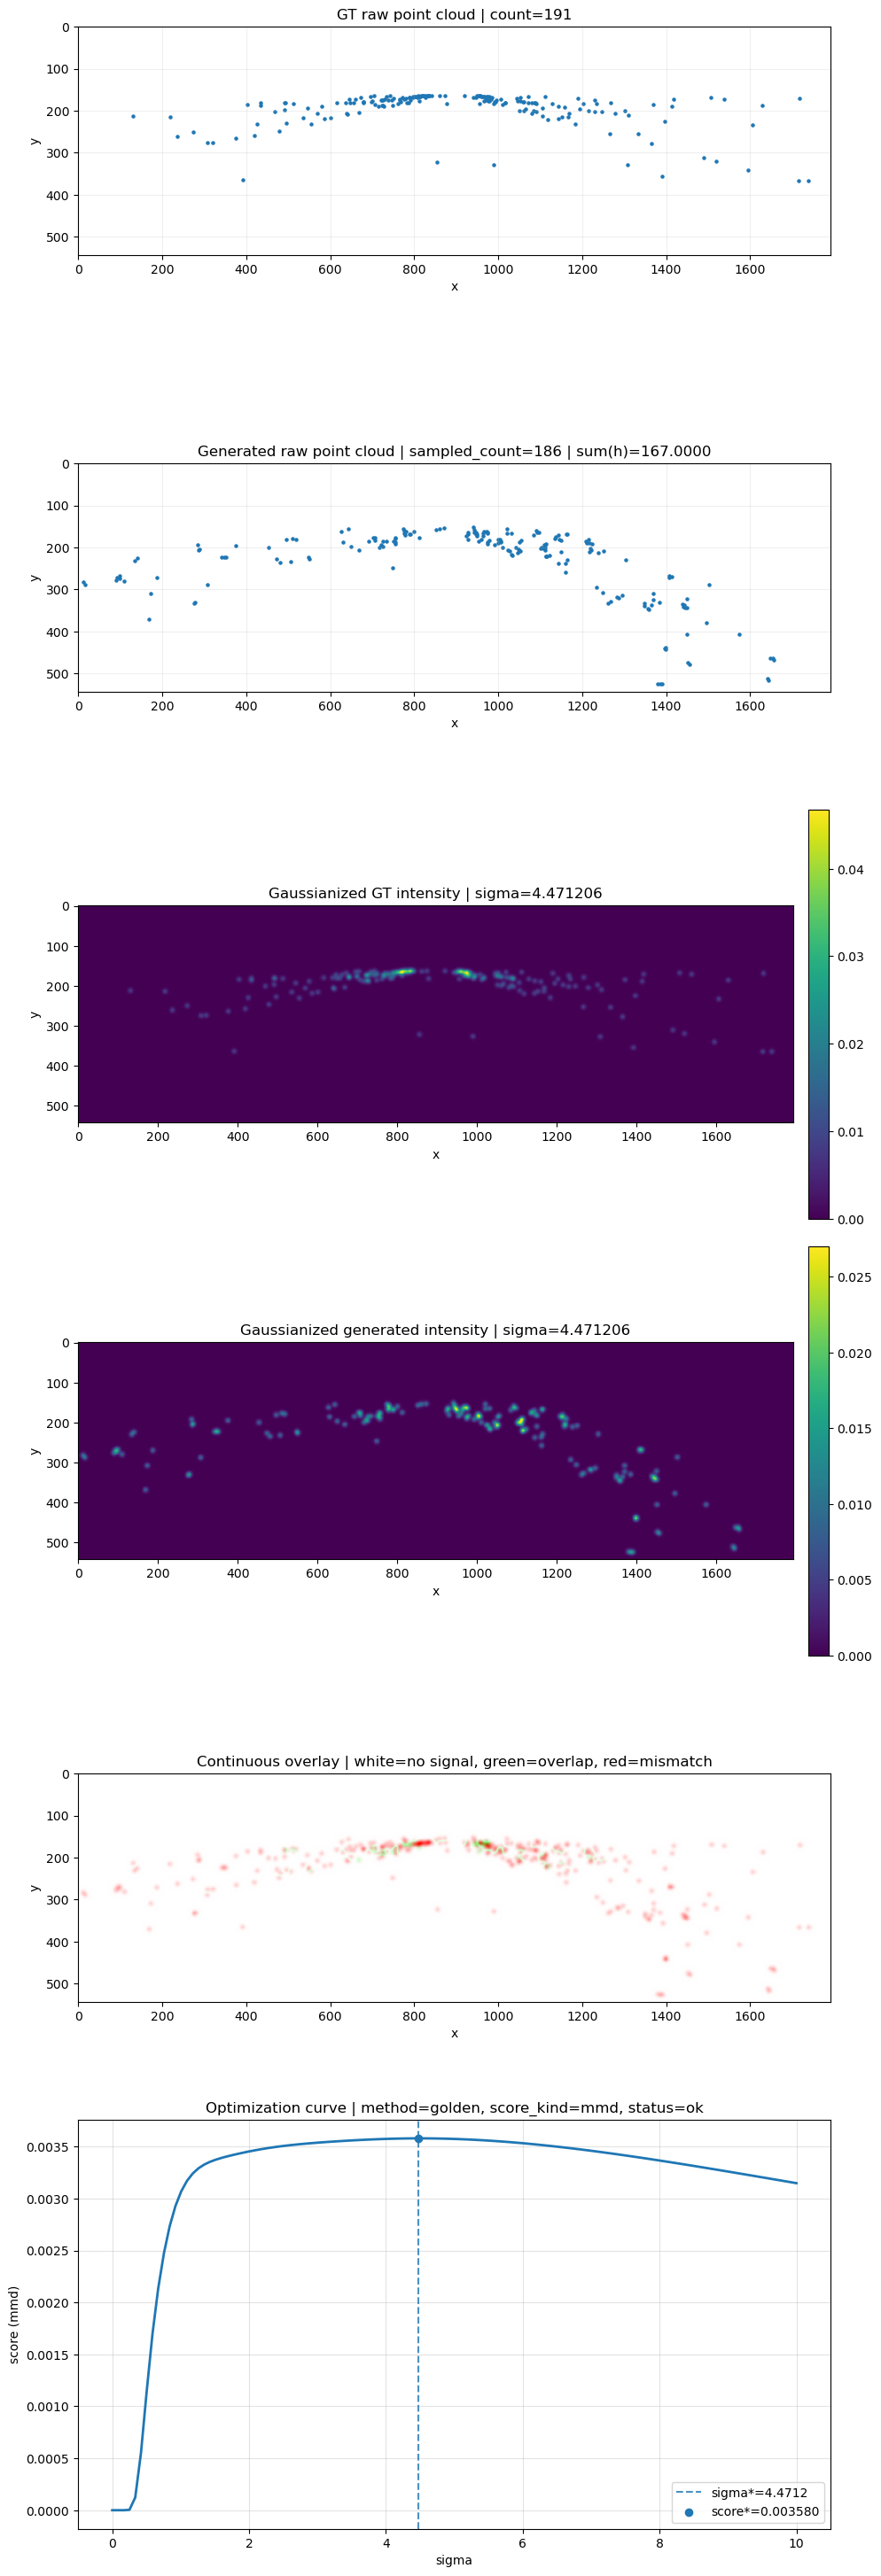

In [63]:
out = plot_gt_input_and_optimal_blur(
    grid=grid,
    gt_support=gt_support,
    method="golden",
    score_kind="mmd",
    run_kwargs=dict(
        sigma_min=0.0,
        sigma_max=120.0,
        max_iter=30,
        tol_sigma=0.5,
    ),
    rng_seed=0,
)